In [117]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt


In [118]:
data=pd.read_csv("loan_approval_data.csv")

In [119]:
data.head()

,Applicant_ID,Applicant_Income,Coapplicant_Income,Employment_Status,Age,Marital_Status,Dependents,Credit_Score,Existing_Loans,DTI_Ratio,Savings,Collateral_Value,Loan_Amount,Loan_Term,Loan_Purpose,Property_Area,Education_Level,Gender,Employer_Category,Loan_Approved
0,1.0,17795.0,1387.0,Salaried,51.0,Married,0.0,637.0,4.0,0.53,19403.0,45638.0,16619.0,84.0,Personal,Urban,Not Graduate,Female,Private,No
1,2.0,2860.0,2679.0,Salaried,46.0,Married,3.0,621.0,2.0,0.30,2580.0,49272.0,38687.0,NaN,Car,Semiurban,Graduate,NaN,Private,No
2,3.0,7390.0,2106.0,Salaried,25.0,Single,2.0,674.0,4.0,0.20,13844.0,6908.0,27943.0,72.0,NaN,Urban,NaN,Female,Government,Yes
3,4.0,13964.0,8173.0,Salaried,40.0,Married,2.0,579.0,3.0,0.31,9553.0,10844.0,27819.0,60.0,Business,Rural,Graduate,Female,Government,No
4,5.0,13284.0,4223.0,Self-employed,31.0,Single,2.0,721.0,1.0,0.29,9386.0,37629.0,12741.0,72.0,Car,NaN,Graduate,Male,Private,Yes


In [120]:
data.columns

Index(['Applicant_ID', 'Applicant_Income', 'Coapplicant_Income',
       'Employment_Status', 'Age', 'Marital_Status', 'Dependents',
       'Credit_Score', 'Existing_Loans', 'DTI_Ratio', 'Savings',
       'Collateral_Value', 'Loan_Amount', 'Loan_Term', 'Loan_Purpose',
       'Property_Area', 'Education_Level', 'Gender', 'Employer_Category',
       'Loan_Approved'],
      dtype='object')

In [121]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 20 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   Applicant_ID        950 non-null    float64
 1   Applicant_Income    950 non-null    float64
 2   Coapplicant_Income  950 non-null    float64
 3   Employment_Status   950 non-null    object 
 4   Age                 950 non-null    float64
 5   Marital_Status      950 non-null    object 
 6   Dependents          950 non-null    float64
 7   Credit_Score        950 non-null    float64
 8   Existing_Loans      950 non-null    float64
 9   DTI_Ratio           950 non-null    float64
 10  Savings             950 non-null    float64
 11  Collateral_Value    950 non-null    float64
 12  Loan_Amount         950 non-null    float64
 13  Loan_Term           950 non-null    float64
 14  Loan_Purpose        950 non-null    object 
 15  Property_Area       950 non-null    object 
 16  Educati

In [122]:
data.isnull().sum()

,0
Applicant_ID,50
Applicant_Income,50
Coapplicant_Income,50
Employment_Status,50
Age,50
Marital_Status,50
Dependents,50
Credit_Score,50
Existing_Loans,50
DTI_Ratio,50


In [123]:
data.describe()

,Applicant_ID,Applicant_Income,Coapplicant_Income,Age,Dependents,Credit_Score,Existing_Loans,DTI_Ratio,Savings,Collateral_Value,Loan_Amount,Loan_Term
count,950.000000,950.000000,950.000000,950.000000,950.000000,950.000000,950.000000,950.000000,950.000000,950.000000,950.000000,950.000000
mean,501.220000,10852.571579,5082.455789,39.971579,1.474737,676.033684,1.950526,0.347263,9940.452632,24802.792632,20522.825263,48.000000
std,289.608451,5061.632859,2943.161570,11.139797,1.105067,71.346015,1.406246,0.144341,5860.736885,14345.696031,11504.142575,24.245322
min,1.000000,2009.000000,1.000000,21.000000,0.000000,550.000000,0.000000,0.100000,65.000000,36.000000,1015.000000,12.000000
25%,250.250000,6730.750000,2472.750000,30.250000,1.000000,616.250000,1.000000,0.220000,4760.250000,12698.250000,9806.250000,24.000000
50%,499.500000,10548.000000,5205.500000,40.000000,1.000000,678.000000,2.000000,0.340000,9880.500000,24321.000000,21210.500000,48.000000
75%,752.750000,15190.000000,7620.750000,49.000000,2.000000,737.000000,3.000000,0.480000,15074.500000,36947.000000,30263.000000,72.000000
max,1000.000000,19988.000000,9996.000000,59.000000,3.000000,799.000000,4.000000,0.600000,19996.000000,49954.000000,39995.000000,84.000000


In [124]:
data.sample(2)

,Applicant_ID,Applicant_Income,Coapplicant_Income,Employment_Status,Age,Marital_Status,Dependents,Credit_Score,Existing_Loans,DTI_Ratio,Savings,Collateral_Value,Loan_Amount,Loan_Term,Loan_Purpose,Property_Area,Education_Level,Gender,Employer_Category,Loan_Approved
973,974.0,17070.0,3302.0,Self-employed,55.0,Married,0.0,552.0,4.0,0.26,15439.0,6998.0,3696.0,48.0,Education,Urban,Not Graduate,Male,Business,No
471,472.0,11580.0,8907.0,Contract,57.0,Married,0.0,622.0,0.0,0.33,1234.0,25651.0,34071.0,36.0,Personal,Semiurban,Graduate,NaN,Government,No


# To handle missing values...

In [125]:
categorical_data=data.select_dtypes(include=["object"]).columns

# numerical_data=data.select_dtypes(include=["float64","int64"]).columns
numerical_data=data.select_dtypes(include=["number"]).columns



In [126]:
categorical_data

Index(['Employment_Status', 'Marital_Status', 'Loan_Purpose', 'Property_Area',
       'Education_Level', 'Gender', 'Employer_Category', 'Loan_Approved'],
      dtype='object')

In [127]:
numerical_data

Index(['Applicant_ID', 'Applicant_Income', 'Coapplicant_Income', 'Age',
       'Dependents', 'Credit_Score', 'Existing_Loans', 'DTI_Ratio', 'Savings',
       'Collateral_Value', 'Loan_Amount', 'Loan_Term'],
      dtype='object')

In [128]:
categorical_data.size+numerical_data.size

20

In [129]:
from sklearn.impute import SimpleImputer
num_imp=SimpleImputer(strategy="mean")
data[numerical_data]=num_imp.fit_transform(data[numerical_data])


In [130]:
categorical_imp=SimpleImputer(strategy="most_frequent")
data[categorical_data]=categorical_imp.fit_transform(data[categorical_data])

In [131]:
data.isna().sum()

,0
Applicant_ID,0
Applicant_Income,0
Coapplicant_Income,0
Employment_Status,0
Age,0
Marital_Status,0
Dependents,0
Credit_Score,0
Existing_Loans,0
DTI_Ratio,0


EDA

In [132]:
# how balanced our classes are?
classes_count=data["Loan_Approved"].value_counts()

Text(0.5, 1.0, 'Is Loan approval or not ?')

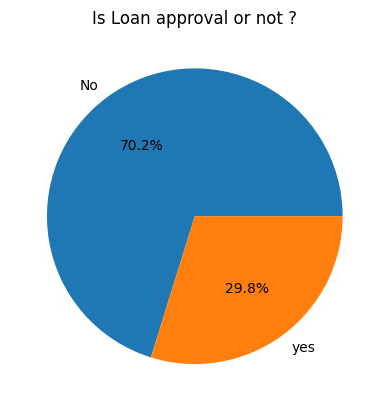

In [133]:
plt.pie(classes_count,labels=["No","yes"],autopct="%1.1f%%")
plt.title("Is Loan approval or not ?")


[Text(0, 0, '722'), Text(0, 0, '278')]

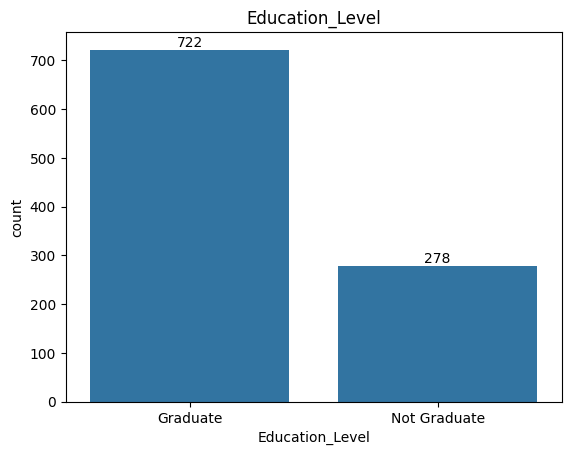

In [134]:
gender_count=data["Education_Level"].value_counts()
ax=sns.barplot(gender_count)
plt.title("Education_Level")
ax.bar_label(ax.containers[0])


[Text(0, 0, '621'), Text(0, 0, '379')]

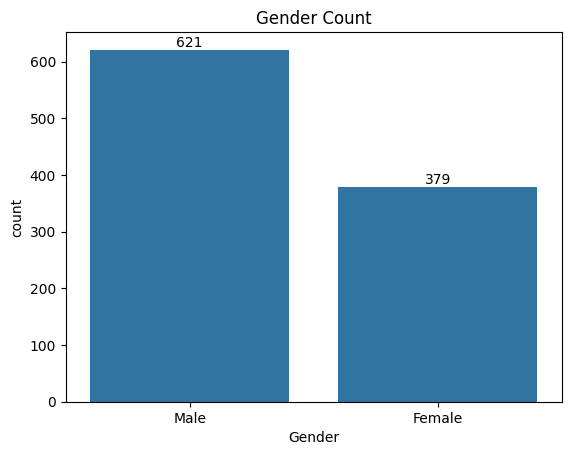

In [135]:
gender_count=data["Gender"].value_counts()
ax=sns.barplot(gender_count)
plt.title("Gender Count")
ax.bar_label(ax.containers[0])

<Axes: xlabel='Applicant_Income', ylabel='Count'>

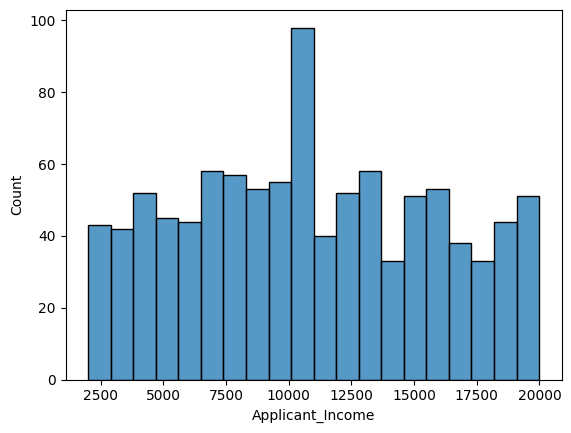

In [136]:
sns.histplot(
    data=data,
    x="Applicant_Income",
    bins=20
)

<Axes: xlabel='Coapplicant_Income', ylabel='Count'>

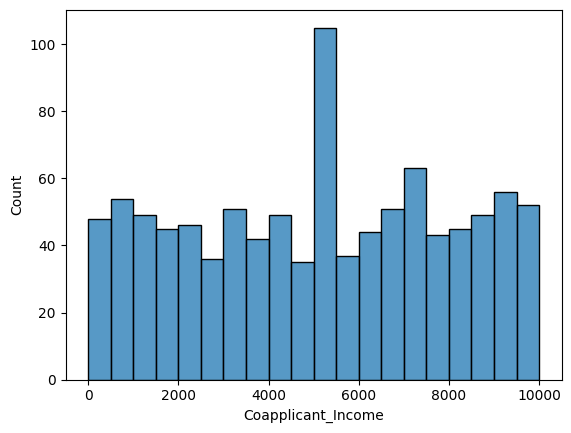

In [137]:
sns.histplot(
    data=data,
    x="Coapplicant_Income",
    bins=20
)

<Axes: xlabel='Loan_Approved', ylabel='Applicant_Income'>

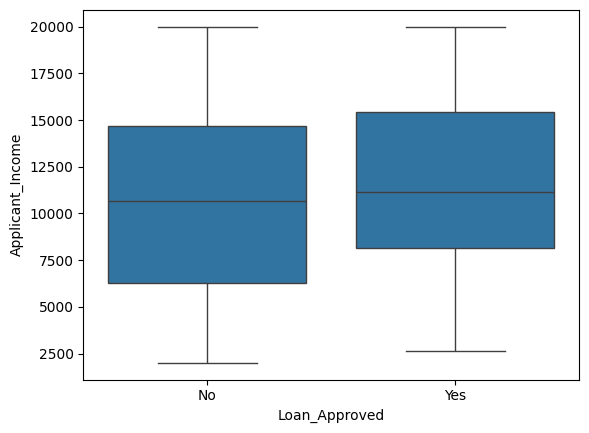

In [138]:
sns.boxplot(
    data=data,
    x="Loan_Approved",
    y="Applicant_Income"
)

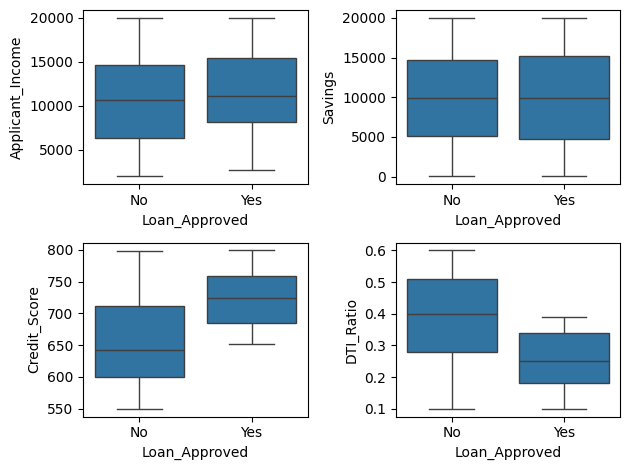

In [139]:
fig,axis=plt.subplots(2,2)
sns.boxplot(ax=axis[0,0],data=data,x="Loan_Approved",y="Applicant_Income")
sns.boxplot(ax=axis[0,1],data=data,x="Loan_Approved",y="Savings")
sns.boxplot(ax=axis[1,0],data=data,x="Loan_Approved",y="Credit_Score")
sns.boxplot(ax=axis[1,1],data=data,x="Loan_Approved",y="DTI_Ratio")


plt.tight_layout()



<Axes: xlabel='Credit_Score', ylabel='Count'>

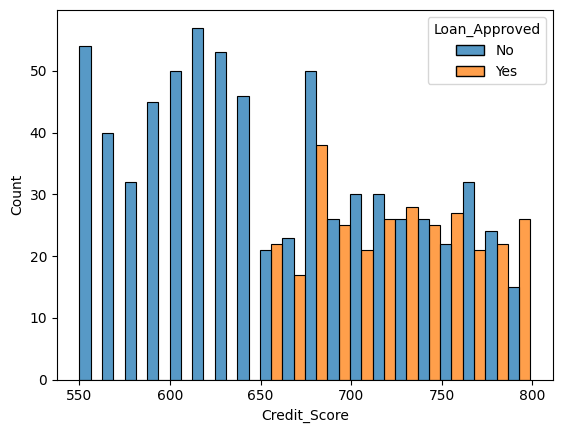

In [140]:
sns.histplot(
    data=data,
    x="Credit_Score",
    hue="Loan_Approved",
    bins=20,
    multiple="dodge"
)

In [141]:
data=data.drop("Applicant_ID",axis=1)

In [142]:
data.head()

,Applicant_Income,Coapplicant_Income,Employment_Status,Age,Marital_Status,Dependents,Credit_Score,Existing_Loans,DTI_Ratio,Savings,Collateral_Value,Loan_Amount,Loan_Term,Loan_Purpose,Property_Area,Education_Level,Gender,Employer_Category,Loan_Approved
0,17795.0,1387.0,Salaried,51.0,Married,0.0,637.0,4.0,0.53,19403.0,45638.0,16619.0,84.0,Personal,Urban,Not Graduate,Female,Private,No
1,2860.0,2679.0,Salaried,46.0,Married,3.0,621.0,2.0,0.30,2580.0,49272.0,38687.0,48.0,Car,Semiurban,Graduate,Male,Private,No
2,7390.0,2106.0,Salaried,25.0,Single,2.0,674.0,4.0,0.20,13844.0,6908.0,27943.0,72.0,Business,Urban,Graduate,Female,Government,Yes
3,13964.0,8173.0,Salaried,40.0,Married,2.0,579.0,3.0,0.31,9553.0,10844.0,27819.0,60.0,Business,Rural,Graduate,Female,Government,No
4,13284.0,4223.0,Self-employed,31.0,Single,2.0,721.0,1.0,0.29,9386.0,37629.0,12741.0,72.0,Car,Urban,Graduate,Male,Private,Yes


Encoding

In [143]:
from sklearn.preprocessing import LabelEncoder,OneHotEncoder

In [144]:
data["Marital_Status"].unique()

array(['Married', 'Single'], dtype=object)

In [145]:
le=LabelEncoder()
label_data=["Loan_Approved","Gender","Marital_Status"]
for col in label_data:
    data[col]=le.fit_transform(data[col])

In [146]:
cols_data=["Employment_Status","Loan_Purpose","Property_Area","Education_Level","Employer_Category"]
ohe=OneHotEncoder(drop="first",sparse_output=False,handle_unknown="ignore")
encoded_data=ohe.fit_transform(data[cols_data])
encoded_df=pd.DataFrame(encoded_data,columns=ohe.get_feature_names_out(cols_data),index=data.index)
data=pd.concat([data.drop(columns=cols_data),encoded_df],axis=1)

In [147]:
data.head()

,Applicant_Income,Coapplicant_Income,Age,Marital_Status,Dependents,Credit_Score,Existing_Loans,DTI_Ratio,Savings,Collateral_Value,...,Loan_Purpose_Education,Loan_Purpose_Home,Loan_Purpose_Personal,Property_Area_Semiurban,Property_Area_Urban,Education_Level_Not Graduate,Employer_Category_Government,Employer_Category_MNC,Employer_Category_Private,Employer_Category_Unemployed
0,17795.0,1387.0,51.0,0,0.0,637.0,4.0,0.53,19403.0,45638.0,...,0.0,0.0,1.0,0.0,1.0,1.0,0.0,0.0,1.0,0.0
1,2860.0,2679.0,46.0,0,3.0,621.0,2.0,0.30,2580.0,49272.0,...,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0
2,7390.0,2106.0,25.0,1,2.0,674.0,4.0,0.20,13844.0,6908.0,...,0.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0
3,13964.0,8173.0,40.0,0,2.0,579.0,3.0,0.31,9553.0,10844.0,...,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0
4,13284.0,4223.0,31.0,1,2.0,721.0,1.0,0.29,9386.0,37629.0,...,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0


In [148]:
df=data.select_dtypes(include="number")
corr_metrix=df.corr()

In [149]:
df.corr()["Loan_Approved"].sort_values(ascending=False)

,Loan_Approved
Loan_Approved,1.000000
Credit_Score,0.451175
Applicant_Income,0.119796
Employer_Category_MNC,0.069049
Loan_Purpose_Personal,0.034043
Marital_Status,0.030182
Property_Area_Urban,0.025963
Collateral_Value,0.021868
Coapplicant_Income,0.004230
Loan_Purpose_Home,0.002118


<Axes: >

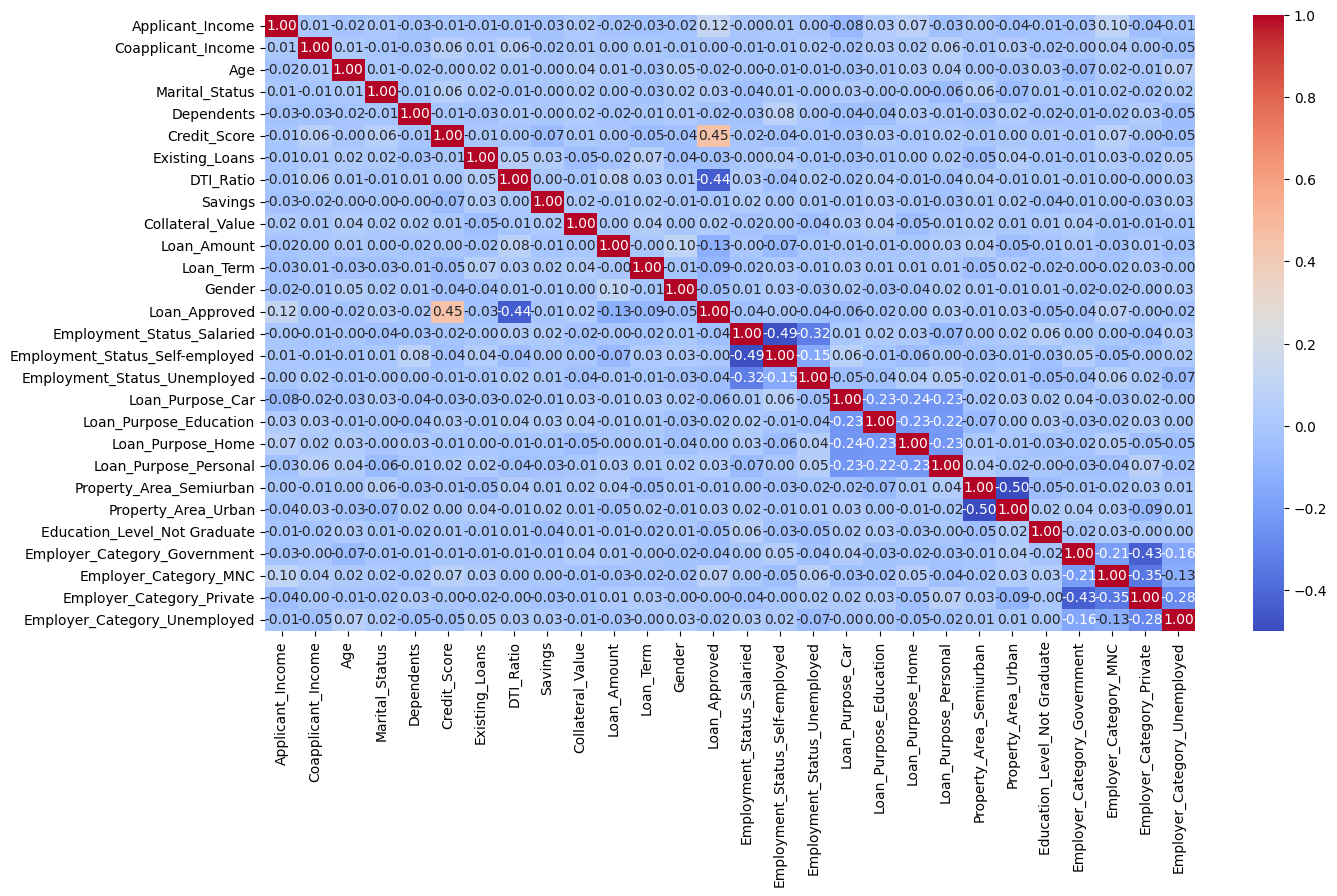

In [150]:
plt.figure(figsize=(15,8))
sns.heatmap(
    corr_metrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)


In [151]:
data.head()


,Applicant_Income,Coapplicant_Income,Age,Marital_Status,Dependents,Credit_Score,Existing_Loans,DTI_Ratio,Savings,Collateral_Value,...,Loan_Purpose_Education,Loan_Purpose_Home,Loan_Purpose_Personal,Property_Area_Semiurban,Property_Area_Urban,Education_Level_Not Graduate,Employer_Category_Government,Employer_Category_MNC,Employer_Category_Private,Employer_Category_Unemployed
0,17795.0,1387.0,51.0,0,0.0,637.0,4.0,0.53,19403.0,45638.0,...,0.0,0.0,1.0,0.0,1.0,1.0,0.0,0.0,1.0,0.0
1,2860.0,2679.0,46.0,0,3.0,621.0,2.0,0.30,2580.0,49272.0,...,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0
2,7390.0,2106.0,25.0,1,2.0,674.0,4.0,0.20,13844.0,6908.0,...,0.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0
3,13964.0,8173.0,40.0,0,2.0,579.0,3.0,0.31,9553.0,10844.0,...,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0
4,13284.0,4223.0,31.0,1,2.0,721.0,1.0,0.29,9386.0,37629.0,...,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0


In [152]:
# training the dataset
X=data.drop("Loan_Approved",axis=1)
y=data["Loan_Approved"]

In [153]:
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split


In [154]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.33, random_state=42)

In [155]:
scaler=StandardScaler()
X_train_scale=scaler.fit_transform(X_train)
X_test_scale=scaler.transform(X_test)

In [156]:
# Train and Evaluting our model
from sklearn.linear_model import LogisticRegression
model_1=LogisticRegression()
model_1.fit(X_train_scale,y_train)
y_pred=model_1.predict(X_test_scale)

In [157]:
print("X_train_scale:", X_train_scale.shape)
print("X_test_scale:", X_test_scale.shape)

print("y_train:", y_train.shape)
print("y_test:", y_test.shape)

print("y_pred:", y_pred.shape)

X_train_scale: (670, 27)
X_test_scale: (330, 27)
y_train: (670,)
y_test: (330,)
y_pred: (330,)


In [158]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
print("Accuracy Score:", accuracy_score(y_test, y_pred))
print("Precision Score:", precision_score(y_test, y_pred, average='macro'))
print("Recall Score:", recall_score(y_test, y_pred, average='macro'))
print("F1 Score:", f1_score(y_test, y_pred, average='macro'))





Accuracy Score: 0.8666666666666667
Precision Score: 0.8603154168007725
Recall Score: 0.8284229495830016
F1 Score: 0.8412698412698413


In [159]:
from sklearn.neighbors import KNeighborsClassifier
model_2=KNeighborsClassifier(n_neighbors=7)
model_2.fit(X_train_scale,y_train)
y_pred_1=model_2.predict(X_test_scale)

In [160]:
print("Accuracy Score:", accuracy_score(y_test, y_pred_1))
print("Precision Score:", precision_score(y_test, y_pred_1, average='macro'))
print("Recall Score:", recall_score(y_test, y_pred_1, average='macro'))
print("F1 Score:", f1_score(y_test, y_pred_1, average='macro'))


Accuracy Score: 0.7696969696969697
Precision Score: 0.7636662806996161
Recall Score: 0.6813209840325217
F1 Score: 0.6965737514518002


In [161]:
from sklearn.naive_bayes import GaussianNB
model_3=GaussianNB()
model_3.fit(X_train_scale,y_train)
y_pred_2=model_2.predict(X_test_scale)

In [162]:
print("Accuracy Score:", accuracy_score(y_test, y_pred_2))
print("Precision Score:", precision_score(y_test, y_pred_2, average='macro'))
print("Recall Score:", recall_score(y_test, y_pred_2, average='macro'))
print("F1 Score:", f1_score(y_test, y_pred_2, average='macro'))


Accuracy Score: 0.7696969696969697
Precision Score: 0.7636662806996161
Recall Score: 0.6813209840325217
F1 Score: 0.6965737514518002


In [163]:
import joblib
from google.colab import files
joblib.dump(model_1,"model.pkl")
files.download('model.pkl')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [164]:
import joblib

joblib.dump(scaler, "scaler.pkl")

from google.colab import files
files.download("scaler.pkl")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [165]:
data.columns

Index(['Applicant_Income', 'Coapplicant_Income', 'Age', 'Marital_Status',
       'Dependents', 'Credit_Score', 'Existing_Loans', 'DTI_Ratio', 'Savings',
       'Collateral_Value', 'Loan_Amount', 'Loan_Term', 'Gender',
       'Loan_Approved', 'Employment_Status_Salaried',
       'Employment_Status_Self-employed', 'Employment_Status_Unemployed',
       'Loan_Purpose_Car', 'Loan_Purpose_Education', 'Loan_Purpose_Home',
       'Loan_Purpose_Personal', 'Property_Area_Semiurban',
       'Property_Area_Urban', 'Education_Level_Not Graduate',
       'Employer_Category_Government', 'Employer_Category_MNC',
       'Employer_Category_Private', 'Employer_Category_Unemployed'],
      dtype='object')

In [168]:
data.head(3)

,Applicant_Income,Coapplicant_Income,Age,Marital_Status,Dependents,Credit_Score,Existing_Loans,DTI_Ratio,Savings,Collateral_Value,...,Loan_Purpose_Education,Loan_Purpose_Home,Loan_Purpose_Personal,Property_Area_Semiurban,Property_Area_Urban,Education_Level_Not Graduate,Employer_Category_Government,Employer_Category_MNC,Employer_Category_Private,Employer_Category_Unemployed
0,17795.0,1387.0,51.0,0,0.0,637.0,4.0,0.53,19403.0,45638.0,...,0.0,0.0,1.0,0.0,1.0,1.0,0.0,0.0,1.0,0.0
1,2860.0,2679.0,46.0,0,3.0,621.0,2.0,0.30,2580.0,49272.0,...,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0
2,7390.0,2106.0,25.0,1,2.0,674.0,4.0,0.20,13844.0,6908.0,...,0.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0
